# Peculiar-velocity covariance in factorized form

Correlated peculiar velocities of SNe Ia add an $N \times N$ covariance to the Hubble diagram. FLIP (Ravoux et al., arXiv:2501.16852) computes it. Here we test whether it can be written in the factorized form used by SNANA, $C = D + B B^T$ with $D$ diagonal and $B$ of size $N \times K$, so that the likelihood is evaluated with the Woodbury identity.

Questions answered below:

1. How many modes does the FLIP covariance need, and does that grow with $N$?
2. Which way of building $B$ gives an unbiased $f\sigma_8$?
3. How much faster is the factorized likelihood than a dense Cholesky?

Everything runs on a synthetic sample with the power spectrum bundled with FLIP, so the numbers show the method and are not a forecast.

In [1]:
import os, sys
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(v, "8")          # shared login nodes expose hundreds of cores

import numpy as np
import scipy.linalg
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "src"))
import vpec_cov
from factorized_likelihood import FactorizedCovariance

import io, logging, contextlib
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    vpec_cov._import_flip()                # FLIP prints a banner and log lines on import
logging.getLogger().setLevel(logging.ERROR)
logging.getLogger("matplotlib").setLevel(logging.WARNING)

plt.rcParams.update({"font.size": 15, "xtick.direction": "in", "ytick.direction": "in",
                     "xtick.top": True, "ytick.right": True, "figure.dpi": 100})
OUT = os.path.join(ROOT, "outputs")

## 1. FLIP covariance for a sample

FLIP takes (RA, Dec, comoving distance from $z_{\rm CMB}$) and a power spectrum, and returns

$$C_{vv} = (f\sigma_8)^2\, P + \sigma_v^2 \, I .$$

$P$ is computed once. The velocity covariance is then converted to distance-modulus shifts with $\Delta\mu = \frac{5}{\ln 10}\frac{1+z}{z(1+z/2)}\frac{v}{c}$. To use a FITRES file, replace the synthetic sample with `vpec_cov.read_fitres(path, ("RA", "DEC", "zCMB"))`.

In [2]:
rng = np.random.default_rng(1)
N, SIGMA_MU, FS8_TRUE = 1500, 0.12, 0.4

ra  = rng.uniform(0, 360, N)
dec = np.degrees(np.arcsin(rng.uniform(-1, 1, N)))
z   = rng.uniform(0.02, 0.10, N)

P_v = vpec_cov.flip_vv_covariance(ra, dec, z)            # (km/s)^2 at fs8 = 1
F   = vpec_cov.vpec_to_dmu(z)
P   = P_v * np.outer(F, F)                               # mag^2 at fs8 = 1
d   = np.full(N, SIGMA_MU**2)                            # diagonal D: statistical + intrinsic
print(f"N = {N},  P is {P.shape[0]} x {P.shape[1]}")

N = 1500,  P is 1500 x 1500


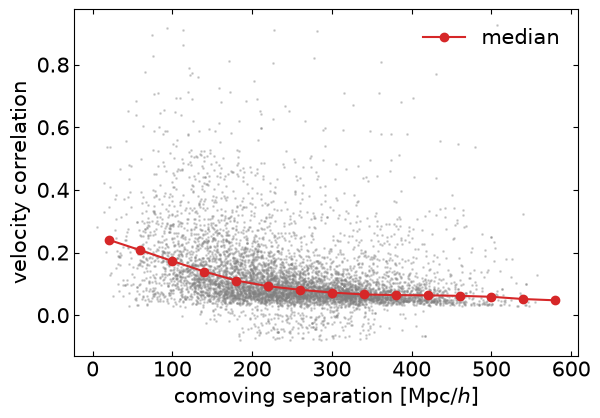

In [3]:
# Velocity correlation versus comoving separation, for random pairs
i, j = rng.integers(0, N, (2, 200000)); keep = i != j; i, j = i[keep], j[keep]
rc = vpec_cov.comoving_distance_mpc_h(z)
X = rc * np.array([np.cos(np.radians(dec)) * np.cos(np.radians(ra)),
                   np.cos(np.radians(dec)) * np.sin(np.radians(ra)), np.sin(np.radians(dec))])
sep = np.linalg.norm(X[:, i] - X[:, j], axis=0)
corr = P_v[i, j] / np.sqrt(P_v[i, i] * P_v[j, j])

bins = np.linspace(0, 600, 16); mid = 0.5 * (bins[1:] + bins[:-1])
med = [np.median(corr[(sep >= lo) & (sep < hi)]) for lo, hi in zip(bins[:-1], bins[1:])]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(sep[::30], corr[::30], ".", ms=2, alpha=0.3, color="gray")
ax.plot(mid, med, "o-", color="C3", label="median")
ax.set_xlabel(r"comoving separation [Mpc/$h$]"); ax.set_ylabel("velocity correlation")
ax.legend(frameon=False); plt.show()

## 2. The covariance is not low-rank

Eigenvalues of $P$, and the number of modes $K$ needed to hold a given fraction of the variance.

modes for 90 / 99 / 99.9 % of the variance: 184 / 818 / 1240   (N = 1500)


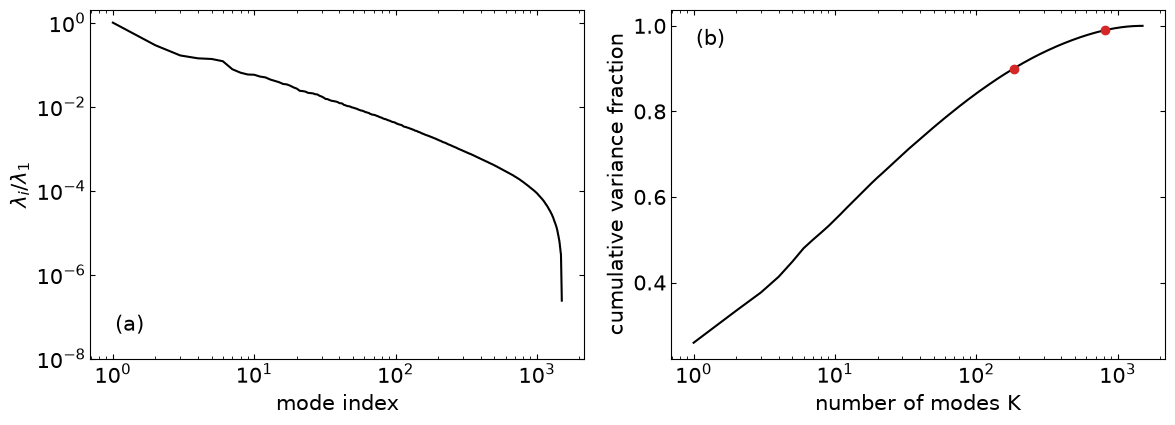

In [4]:
eig = vpec_cov.eigh_sorted(P)                            # computed once, reused below
ev = eig[0][::-1]
K90, K99, K999 = (vpec_cov.n_modes_for_variance(ev, f) for f in (0.9, 0.99, 0.999))
print(f"modes for 90 / 99 / 99.9 % of the variance: {K90} / {K99} / {K999}   (N = {N})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].loglog(np.arange(1, N + 1), np.clip(ev, 1e-12, None) / ev[0], color="k")
ax[0].set_xlabel("mode index"); ax[0].set_ylabel(r"$\lambda_i / \lambda_1$"); ax[0].set_ylim(1e-8, 2)
ax[0].text(0.05, 0.08, "(a)", transform=ax[0].transAxes)
ax[1].semilogx(np.arange(1, N + 1), np.cumsum(np.clip(ev, 0, None)) / np.clip(ev, 0, None).sum(), color="k")
for k, f in ((K90, 0.9), (K99, 0.99)):
    ax[1].plot([k], [f], "o", color="C3")
ax[1].set_xlabel("number of modes K"); ax[1].set_ylabel("cumulative variance fraction")
ax[1].text(0.05, 0.9, "(b)", transform=ax[1].transAxes)
plt.tight_layout(); plt.show()

## 3. Factorized form and the three ways to build $B$

With $C = D + B B^T$ the Woodbury identity and the determinant lemma give

$$C^{-1} = D^{-1} - D^{-1}B\,(I + B^T D^{-1} B)^{-1} B^T D^{-1}, \qquad \ln|C| = \ln|D| + \ln|I + B^T D^{-1} B|,$$

so only a $K \times K$ matrix is factorized. Since $f\sigma_8$ only rescales $P$, the columns are built once at $f\sigma_8 = 1$ and $B(f\sigma_8) = f\sigma_8\, B_1$.

| method | construction | needs |
|---|---|---|
| `eig` | top-$K$ eigenmodes | full eigendecomposition |
| `rsvd` | randomized range finder on $P$ (about 4 products $P\,[N\times K]$) | $P$ in memory |
| `mc` | $K$ random draws $x_j \sim \mathcal N(0, P)$, $B = [x_j]/\sqrt K$ | a sampler |

**Remainder correction.** Dropping modes lowers $\ln|C|$. Adding the diagonal of what $B B^T$ misses back into $D$ removes most of that bias: $D \to D + (f\sigma_8)^2\,{\rm diag}(P - B_1 B_1^T)$.

In [5]:
K = 200
B_eig  = vpec_cov.eigen_B(P, K, eig)
B_rsvd = vpec_cov.randomized_B(P, K, np.random.default_rng(5))
B_mc   = vpec_cov.monte_carlo_B(P, K, np.random.default_rng(5), eig)
methods = {"eig": B_eig, "rsvd": B_rsvd, "mc": B_mc}

C_true = np.diag(d) + FS8_TRUE**2 * P
r = scipy.linalg.cholesky(C_true, lower=True) @ rng.standard_normal(N)       # one mock residual
ld_true = np.linalg.slogdet(C_true)[1]

print(f"K = {K}:  relative Frobenius error of the signal part, and log|C| error at the true fs8")
for name, B1 in methods.items():
    err = np.linalg.norm(P - B1 @ B1.T) / np.linalg.norm(P)
    rem = vpec_cov.remainder_diag(P, B1)
    ld_off = FactorizedCovariance(d, FS8_TRUE * B1).logdet() - ld_true
    ld_on  = FactorizedCovariance(d + FS8_TRUE**2 * rem, FS8_TRUE * B1).logdet() - ld_true
    print(f"  {name:5s}  ||P - B B^T|| / ||P|| = {err:.3f}   dlogdet: {ld_off:7.2f} (plain)  {ld_on:6.2f} (with remainder)")

K = 200:  relative Frobenius error of the signal part, and log|C| error at the true fs8
  eig    ||P - B B^T|| / ||P|| = 0.014   dlogdet:  -12.02 (plain)   -0.23 (with remainder)
  rsvd   ||P - B B^T|| / ||P|| = 0.017   dlogdet:  -12.77 (plain)   -0.20 (with remainder)
  mc     ||P - B B^T|| / ||P|| = 0.242   dlogdet:   -6.09 (plain)   -0.66 (with remainder)


## 4. Effect on $f\sigma_8$

One mock residual, profile of $-2\ln\mathcal L$ over $f\sigma_8$, dense solve against the factorized forms with the remainder correction ($K=200$).

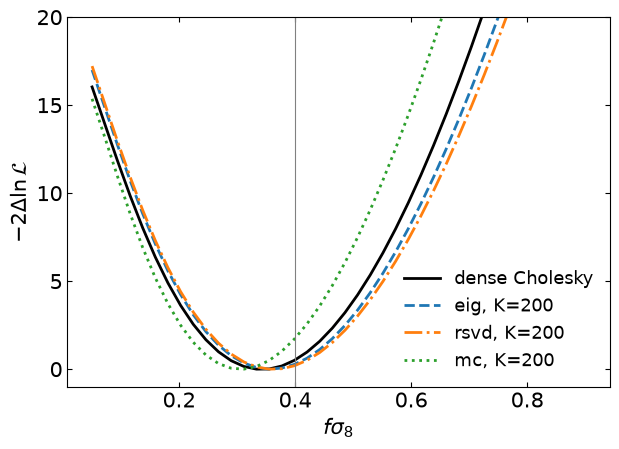

In [6]:
grid = np.linspace(0.05, 0.9, 40)
dense = np.array([vpec_cov.m2lnl_dense(f, r, d, P) for f in grid])
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.plot(grid, dense - dense.min(), "k-", lw=2, label="dense Cholesky")
for (name, B1), ls in zip(methods.items(), ("--", "-.", ":")):
    rem = vpec_cov.remainder_diag(P, B1)
    prof = np.array([vpec_cov.m2lnl_woodbury(f, r, d, B1, rem) for f in grid])
    ax.plot(grid, prof - prof.min(), ls, lw=2, label=f"{name}, K={K}")
ax.axvline(FS8_TRUE, color="gray", lw=0.8)
ax.set_ylim(-1, 20); ax.set_xlabel(r"$f\sigma_8$"); ax.set_ylabel(r"$-2\Delta\ln\mathcal{L}$")
ax.legend(frameon=False, fontsize=13); plt.show()

The profile alone can hide a small shift, so the next figure fits $f\sigma_8$ on 30 mock residuals with the dense and the factorized likelihood and reports the difference in units of the statistical error (`scripts/03_diag_correction.py`, $N=1500$).

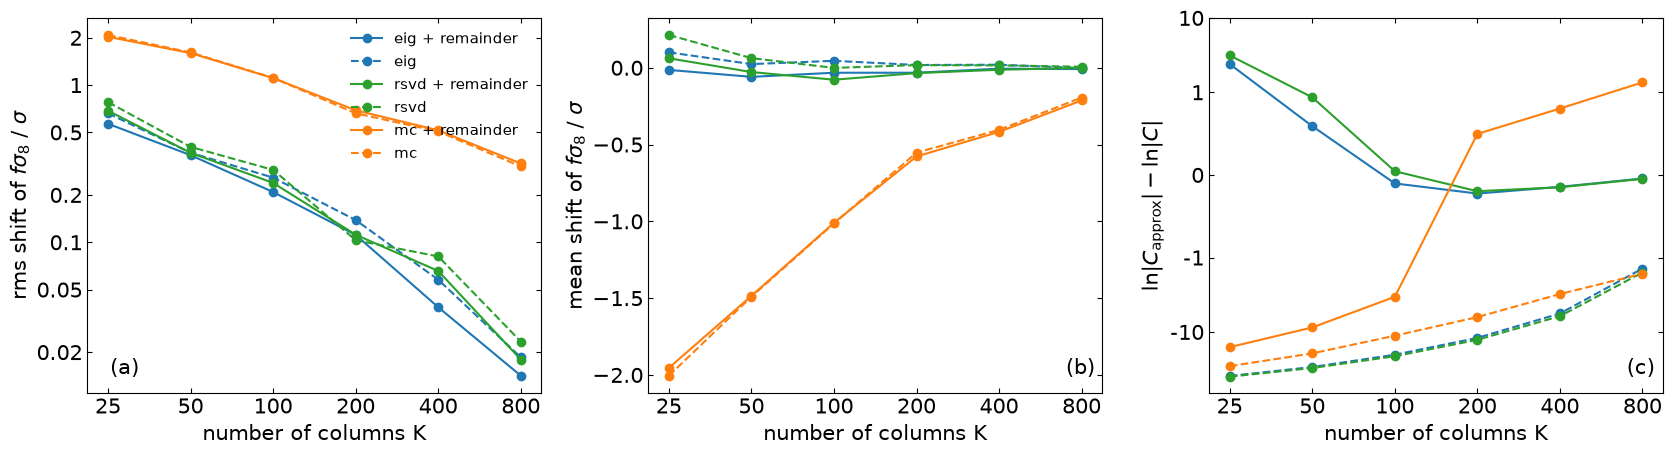

In [7]:
t = np.loadtxt(os.path.join(OUT, "diag_correction_N1500.csv"))     # method corr K mean rms sigratio dlogdet
name = {0: "eig", 1: "rsvd", 2: "mc"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for m, c in ((0, "C0"), (1, "C2"), (2, "C1")):
    for corr, ls in ((1, "-"), (0, "--")):
        s = t[(t[:, 0] == m) & (t[:, 1] == corr)]
        lab = f"{name[m]}" + (" + remainder" if corr else "")
        ax[0].loglog(s[:, 2], s[:, 4], ls, marker="o", color=c, label=lab)
        ax[1].plot(s[:, 2], s[:, 3], ls, marker="o", color=c)
        ax[2].plot(s[:, 2], s[:, 6], ls, marker="o", color=c)
ax[0].set_ylabel(r"rms shift of $f\sigma_8$ / $\sigma$"); ax[1].set_ylabel(r"mean shift of $f\sigma_8$ / $\sigma$")
ax[2].set_ylabel(r"$\ln|C_{\rm approx}| - \ln|C|$"); ax[2].set_yscale("symlog", linthresh=1)
ticks = [25, 50, 100, 200, 400, 800]
for a, l in zip(ax, "abc"):
    a.set_xlabel("number of columns K"); a.text(0.05 if l == "a" else 0.92, 0.05, f"({l})", transform=a.transAxes)
    a.set_xscale("log"); a.set_xticks(ticks); a.set_xticklabels(ticks); a.minorticks_off()
ax[0].set_yticks([0.02, 0.05, 0.1, 0.2, 0.5, 1, 2]); ax[0].set_yticklabels(["0.02", "0.05", "0.1", "0.2", "0.5", "1", "2"])
ax[2].set_yticks([-10, -1, 0, 1, 10]); ax[2].set_yticklabels(["-10", "-1", "0", "1", "10"])
ax[0].legend(frameon=False, fontsize=11, loc="upper right")
plt.tight_layout(); plt.show()

Reading the figure (solid: with remainder, dashed: without):

- **`eig` and `rsvd` with the remainder correction** remove the $\ln|C|$ bias and give an $f\sigma_8$ error of about $0.1\sigma$ at $K=200$ and $0.04$ to $0.07\sigma$ at $K=400$, with no mean shift.
- **`mc` (random realizations)** is biased low, by $-0.7\sigma$ at $K=200$ and $-0.4\sigma$ at $K=400$. The sign and size are the same for different random seeds, so this is a systematic effect of using a finite set of random vectors in a nonlinear likelihood, and it falls only slowly with $K$.

## 5. How the rank grows with $N$

Modes needed for 90, 99 and 99.9% of the variance, for samples at fixed volume (`scripts/02_rank_vs_N.py`).

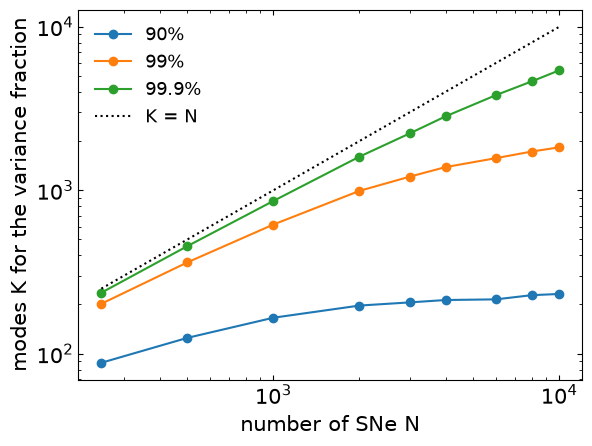

N    K90  K99  K99.9
[[  250    88   202   236]
 [  500   125   362   455]
 [ 1000   166   617   860]
 [ 2000   197   991  1605]
 [ 3000   206  1211  2228]
 [ 4000   213  1385  2830]
 [ 6000   215  1571  3816]
 [ 8000   228  1724  4630]
 [10000   232  1831  5414]]


In [8]:
t = np.loadtxt(os.path.join(OUT, "rank_vs_N.csv"))
fig, ax = plt.subplots(figsize=(6.5, 4.8))
for col, lab in ((1, "90%"), (2, "99%"), (3, "99.9%")):
    ax.loglog(t[:, 0], t[:, col], "o-", label=lab)
ax.loglog(t[:, 0], t[:, 0], "k:", label="K = N")
ax.set_xlabel("number of SNe N"); ax.set_ylabel("modes K for the variance fraction")
ax.legend(frameon=False, fontsize=13); plt.show()
print("N    K90  K99  K99.9"); print(t[:, :4].astype(int))

$K_{90}$ saturates near 230, while $K_{99}$ and $K_{99.9}$ keep growing but more slowly than $N$ (at $N=10^4$: $K_{99}/N = 0.18$). The covariance is not low-rank at the percent level, but the part that matters for $f\sigma_8$ (see section 4) is captured by a few hundred modes.

## 6. Cost of one likelihood evaluation

Dense Cholesky of the $N\times N$ matrix against the factorized solve (`scripts/04_timing_vs_N.py`, 8 threads, shapes only so $B$ is random). `woodbury` rebuilds $B^T D^{-1} B$ on every call, which is needed when $D$ changes (for example $\sigma_v$ free, or the remainder term). `cached` precomputes it and only factorizes the $K\times K$ matrix, which is valid when $D$ is fixed and $f\sigma_8$ only rescales $B$.

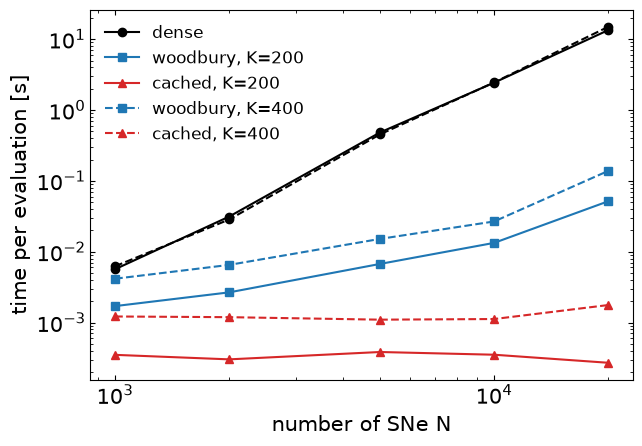

N=10000, K=200: dense    2436 ms, woodbury  13.3 ms (183x), cached  0.35 ms (6940x)
N=10000, K=400: dense    2453 ms, woodbury  26.7 ms (92x), cached  1.12 ms (2190x)


In [9]:
t = np.loadtxt(os.path.join(OUT, "timing_vs_N.csv"))      # N K dense woodbury cached  (seconds)
fig, ax = plt.subplots(figsize=(7, 4.8))
for k, ls in ((200, "-"), (400, "--")):
    s = t[t[:, 1] == k]
    ax.loglog(s[:, 0], s[:, 2], ls, marker="o", color="k", label="dense" if k == 200 else None)
    ax.loglog(s[:, 0], s[:, 3], ls, marker="s", color="C0", label=f"woodbury, K={k}")
    ax.loglog(s[:, 0], s[:, 4], ls, marker="^", color="C3", label=f"cached, K={k}")
ax.set_xlabel("number of SNe N"); ax.set_ylabel("time per evaluation [s]")
ax.legend(frameon=False, fontsize=12); plt.show()
s = t[t[:, 0] == 10000]
for row in s:
    print(f"N=10000, K={int(row[1])}: dense {row[2]*1e3:7.0f} ms, woodbury {row[3]*1e3:5.1f} ms ({row[2]/row[3]:.0f}x), "
          f"cached {row[4]*1e3:5.2f} ms ({row[2]/row[4]:.0f}x)")

## Summary

- The FLIP velocity covariance is not low-rank. $K_{99}$ grows from about 200 at $N=250$ to about 1800 at $N=10^4$, but $K_{90}\approx 230$ stays flat.
- With the **remainder correction**, $K=200$ to $400$ columns from `eig` or `rsvd` reproduce the dense $f\sigma_8$ to about $0.1\sigma$ ($K=200$) and $0.05\sigma$ ($K=400$) at $N=1500$. `rsvd` avoids the full eigendecomposition.
- **Random realizations** (`mc`) are biased low in $f\sigma_8$ at these $K$ and should not be used without a larger $K$ or a bias correction.
- A dense Cholesky costs 2.4 s at $N=10^4$ and 13 s at $N=2\times10^4$. The factorized solve takes 13 to 27 ms (rebuilt) or about 1 ms (cached), so the gain is 100 to 7000 at $N=10^4$, and it only exists for large $N$. Below $N\approx 2000$ a dense solve is already fast.

**Open questions**

1. Accuracy of the factorized form at $N \gtrsim 5000$ with the production power spectrum and the real sample geometry, and for $w_0 w_a$ rather than $f\sigma_8$.
2. A correction for the remaining small bias in `mc`, or a switch to `rsvd` in the SNANA implementation.
3. How $D$ (and the remainder term) should be handled when $\sigma_v$ is fitted.

Reproduce: `scripts/01_vpec_woodbury_demo.py`, `02_rank_vs_N.py`, `03_diag_correction.py`, `04_timing_vs_N.py`. FLIP: arXiv:2501.16852. Factorized covariance: SNANA PR #1797.